# PRDM9 histone feature generation (production)

This notebook converts histone-mark peak calls into **merge-ready interval burden features** for all three window sets:

- `prdm9`
- `datasetA_matched`
- `datasetB_global`

For each histone track, the production feature definition is intentionally narrow and publication-friendly:

- `hmark__<track>__hits` = number of overlapping peaks
- `hmark__<track>__covfrac` = fraction of window bases covered by the **union** of overlapping peaks

The exploratory notebook contained many extra summaries (signal, qValue, summit distance, deltas). For the published feature family, those are intentionally excluded here.

Methodological choices in this production version:

1. **Exact-interval burden only** — no signal-weighted summaries mixed into the feature family.
2. **Union coverage** — overlapping peaks do not inflate `covfrac`.
3. **Exact-duplicate interval removal** within each track — duplicates should not artificially inflate `hits`.
4. **Canonical chromosome filtering** — only `chr1`–`chr22`, `chrX`, `chrY`.
5. **Per-track × per-chromosome parallelization** — scales cleanly to a 64-CPU budget while keeping the overlap logic simple and auditable.


In [4]:

# ------------------------------------------------------------------
# Imports and configuration
# ------------------------------------------------------------------
import os

# Avoid BLAS / OpenMP oversubscription when using many worker processes
for env_var in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[env_var] = "1"

import gc
import json
import math
import logging
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from tqdm.auto import tqdm
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich.logging import RichHandler
from IPython.display import display

console = Console()

N_CPUS = min(64, os.cpu_count() or 1)
CANONICAL_ONLY = True

SAMPLING_DIR = Path("data_prdm9_sampling_production")
PRDM9_BED = SAMPLING_DIR / "prdm9_filtered.bed"
DATASET_A_BED = SAMPLING_DIR / "datasetA_matched.len_gc_entropy.bed"
DATASET_B_BED = SAMPLING_DIR / "datasetB_global.length_only.bed"

HISTONE_TRACKS = {
    "ENCODE_HEK_H3K4me3_R1": "histone_marks/ENCFF498ERO_HEK_H3K4me3_R1_hg38.bed",
    "ENCODE_HEK_H3K4me3_R2": "histone_marks/ENCFF127YXW_HEK_H3K4me3_R2_hg38.bed",
    "ENCODE_HEK_H3K36me3_R1_2": "histone_marks/ENCFF224LEB_HEK_H3K36me3_R1_2_hg38.bed",
    "HEK_H3K4me3_untransfected": "histone_marks/HEK293_H3K4me3_untransfected.bed",
    "HEK_H3K4me3_PRDM9_transfected": "histone_marks/HEK293_H3K4me3_PRDM9-B_HA_transfected.bed",
    "HEK_H3K36me3_untransfected": "histone_marks/HEK293_H3K36me3_untransfected.bed",
    "HEK_H3K36me3_PRDM9_transfected": "histone_marks/HEK293_H3K36me3_PRDM9-B-HA_transfected.bed",
}

OUTDIR = Path("data_prdm9_histones_production")
FIGDIR = OUTDIR / "figures"
TABDIR = OUTDIR / "tables"
FEATDIR = OUTDIR / "features"
METADIR = OUTDIR / "metadata"
LOGDIR = OUTDIR / "logs"
for p in [OUTDIR, FIGDIR, TABDIR, FEATDIR, METADIR, LOGDIR]:
    p.mkdir(parents=True, exist_ok=True)

ALL_PARQUET = FEATDIR / "histone_features.parquet"
DEBUG_PARQUET = FEATDIR / "histone_features_with_qc.parquet"
WINDOWSET_SPLIT_PREFIX = FEATDIR / "histone_features"
WINDOWS_TABLE = TABDIR / "all_windows.tsv"
TRACK_METADATA_TABLE = TABDIR / "histone_track_metadata.tsv"
SUMMARY_TABLE = TABDIR / "histone_windowset_summary.tsv"
EFFECT_TABLE = TABDIR / "histone_effect_summary.tsv"
RUN_METADATA_JSON = METADIR / "run_metadata.json"
LOG_PATH = LOGDIR / "histone_feature_generation.log"

PALETTE_WINDOWSET = {
    "prdm9": "#5B2A86",
    "datasetA_matched": "#1B9E77",
    "datasetB_global": "#D95F02",
}

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

logger = logging.getLogger("prdm9_histones")
logger.setLevel(logging.INFO)
logger.handlers.clear()
logger.addHandler(RichHandler(rich_tracebacks=True, markup=True, show_time=True, show_path=False))
logger.addHandler(logging.FileHandler(LOG_PATH, mode="w"))

console.print(Panel.fit(
    "\n".join([
        "[bold]PRDM9 histone feature generation[/bold]",
        f"CPU budget: {N_CPUS}",
        f"Canonical chromosomes only: {CANONICAL_ONLY}",
        f"Tracks: {len(HISTONE_TRACKS)}",
        f"Output directory: {OUTDIR.resolve()}",
    ]),
    title="Run configuration"
))
logger.info("Starting histone feature generation notebook")


╭─────────────────────────── Run configuration ───────────────────────────╮
│ PRDM9 histone feature generation                                        │
│ CPU budget: 64                                                          │
│ Canonical chromosomes only: True                                        │
│ Tracks: 7                                                               │
│ Output directory: /home/jovyan/prdm9_new/data_prdm9_histones_production │
╰─────────────────────────────────────────────────────────────────────────╯

[04/17/26 10:31:26] INFO     Starting histone feature generation notebook

In [5]:

# ------------------------------------------------------------------
# Utility helpers
# ------------------------------------------------------------------
def canonical_chromosomes():
    return [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]


def sanitize_track_name(name: str) -> str:
    clean = "".join(ch if ch.isalnum() or ch == "_" else "_" for ch in str(name))
    clean = "_".join([tok for tok in clean.split("_") if tok])
    return clean


def read_bed3(path: Path, windowset_name: str) -> pd.DataFrame:
    df = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2], names=["Chromosome", "Start", "End"])
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)

    if ((df["End"] - df["Start"]) <= 0).any():
        bad = df.loc[(df["End"] - df["Start"]) <= 0].head()
        raise ValueError(f"{path} contains non-positive windows:\n{bad}")

    if CANONICAL_ONLY:
        df = df[df["Chromosome"].isin(canonical_chromosomes())].copy()

    df["WindowSet"] = windowset_name
    return df


def add_window_id(df: pd.DataFrame, start_id: int) -> pd.DataFrame:
    df = df.copy()
    df["window_id"] = np.arange(start_id, start_id + len(df), dtype=np.int64)
    df["window_length_bp"] = (df["End"] - df["Start"]).astype(np.int64)
    return df


def read_histone_track(path: Path, track_name: str) -> tuple[pd.DataFrame, dict]:
    raw = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2], names=["Chromosome", "Start", "End"])
    raw["Chromosome"] = raw["Chromosome"].astype(str)
    raw["Start"] = pd.to_numeric(raw["Start"], errors="coerce").astype("Int64")
    raw["End"] = pd.to_numeric(raw["End"], errors="coerce").astype("Int64")

    meta = {
        "track_name": track_name,
        "track_name_sanitized": sanitize_track_name(track_name),
        "path": str(path),
        "n_raw_rows": int(len(raw)),
    }

    bad_numeric = raw["Start"].isna() | raw["End"].isna()
    meta["n_bad_numeric_rows"] = int(bad_numeric.sum())
    raw = raw.loc[~bad_numeric].copy()

    raw["Start"] = raw["Start"].astype(np.int64)
    raw["End"] = raw["End"].astype(np.int64)

    non_positive = (raw["End"] <= raw["Start"])
    meta["n_non_positive_rows"] = int(non_positive.sum())
    raw = raw.loc[~non_positive].copy()

    if CANONICAL_ONLY:
        noncanonical = ~raw["Chromosome"].isin(canonical_chromosomes())
        meta["n_non_canonical_rows"] = int(noncanonical.sum())
        raw = raw.loc[~noncanonical].copy()
    else:
        meta["n_non_canonical_rows"] = 0

    raw = raw[["Chromosome", "Start", "End"]].copy()
    dup_mask = raw.duplicated(subset=["Chromosome", "Start", "End"])
    meta["n_exact_duplicate_rows_removed"] = int(dup_mask.sum())
    raw = raw.loc[~dup_mask].copy()

    raw = raw.sort_values(["Chromosome", "Start", "End"], kind="mergesort").reset_index(drop=True)

    raw["peak_length_bp"] = (raw["End"] - raw["Start"]).astype(np.int64)
    meta["n_clean_rows"] = int(len(raw))
    meta["peak_length_median_bp"] = float(raw["peak_length_bp"].median()) if len(raw) else np.nan
    meta["peak_length_mean_bp"] = float(raw["peak_length_bp"].mean()) if len(raw) else np.nan

    chrom_counts = raw["Chromosome"].value_counts().to_dict()
    meta["chromosomes_present"] = int(len(chrom_counts))
    return raw[["Chromosome", "Start", "End"]].copy(), meta


def featcol(track_name: str, metric: str) -> str:
    return f"hmark__{sanitize_track_name(track_name)}__{metric}"


def safe_ratio(num: float, den: float) -> float:
    if pd.isna(num) or pd.isna(den) or den == 0:
        return np.nan
    return float(num / den)


def cohens_d(x: np.ndarray, y: np.ndarray) -> float:
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[np.isfinite(x)]
    y = y[np.isfinite(y)]
    if len(x) < 2 or len(y) < 2:
        return np.nan
    vx = x.var(ddof=1)
    vy = y.var(ddof=1)
    pooled = ((len(x) - 1) * vx + (len(y) - 1) * vy) / (len(x) + len(y) - 2)
    if pooled <= 0:
        return np.nan
    return float((x.mean() - y.mean()) / math.sqrt(pooled))


def quantile_clip_series(s: pd.Series, q_low=0.005, q_high=0.995) -> pd.Series:
    lo, hi = s.quantile([q_low, q_high])
    return s.clip(lower=float(lo), upper=float(hi))


def human_track_label(name: str) -> str:
    mapping = {
        "ENCODE_HEK_H3K4me3_R1": "ENCODE H3K4me3 R1",
        "ENCODE_HEK_H3K4me3_R2": "ENCODE H3K4me3 R2",
        "ENCODE_HEK_H3K36me3_R1_2": "ENCODE H3K36me3",
        "HEK_H3K4me3_untransfected": "H3K4me3 untransf.",
        "HEK_H3K4me3_PRDM9_transfected": "H3K4me3 +PRDM9",
        "HEK_H3K36me3_untransfected": "H3K36me3 untransf.",
        "HEK_H3K36me3_PRDM9_transfected": "H3K36me3 +PRDM9",
    }
    return mapping.get(name, name)


In [6]:

# ------------------------------------------------------------------
# Load windows and histone tracks
# ------------------------------------------------------------------
logger.info("Loading windows from production sampling outputs")

prdm9_df = read_bed3(PRDM9_BED, "prdm9")
datasetA_df = read_bed3(DATASET_A_BED, "datasetA_matched")
datasetB_df = read_bed3(DATASET_B_BED, "datasetB_global")

prdm9_df = add_window_id(prdm9_df, 0)
datasetA_df = add_window_id(datasetA_df, len(prdm9_df))
datasetB_df = add_window_id(datasetB_df, len(prdm9_df) + len(datasetA_df))

windows = pd.concat([prdm9_df, datasetA_df, datasetB_df], ignore_index=True)
windows = windows[["WindowSet", "Chromosome", "Start", "End", "window_length_bp", "window_id"]].copy()

if windows["window_id"].duplicated().any():
    raise ValueError("window_id is not unique")
if windows[["WindowSet", "Chromosome", "Start", "End"]].duplicated().any():
    dup = windows.loc[windows[["WindowSet", "Chromosome", "Start", "End"]].duplicated(keep=False)].head()
    raise ValueError(f"Duplicate windows detected:\n{dup}")

windows.to_csv(WINDOWS_TABLE, sep="\t", index=False)

tbl = Table(title="Window counts")
tbl.add_column("WindowSet")
tbl.add_column("N windows", justify="right")
tbl.add_column("Median length", justify="right")
for ws, sub in windows.groupby("WindowSet", sort=False):
    tbl.add_row(ws, f"{len(sub):,}", f"{int(sub['window_length_bp'].median()):,}")
console.print(tbl)

logger.info("Loaded %s windows total", f"{len(windows):,}")
logger.info("Window counts by set: %s", windows["WindowSet"].value_counts().to_dict())

logger.info("Loading histone tracks")
track_registry = {}
track_meta_rows = []

for track_name, track_path in HISTONE_TRACKS.items():
    path = Path(track_path)
    if not path.exists():
        raise FileNotFoundError(f"Histone track not found: {path}")
    peaks_df, meta = read_histone_track(path, track_name)
    track_registry[track_name] = peaks_df
    track_meta_rows.append(meta)

track_meta_df = pd.DataFrame(track_meta_rows).sort_values("track_name").reset_index(drop=True)
track_meta_df.to_csv(TRACK_METADATA_TABLE, sep="\t", index=False)

tbl = Table(title="Histone track metadata")
tbl.add_column("Track")
tbl.add_column("Clean peaks", justify="right")
tbl.add_column("Dup removed", justify="right")
tbl.add_column("Median peak bp", justify="right")
for _, row in track_meta_df.iterrows():
    tbl.add_row(
        human_track_label(row["track_name"]),
        f"{int(row['n_clean_rows']):,}",
        f"{int(row['n_exact_duplicate_rows_removed']):,}",
        "NA" if pd.isna(row["peak_length_median_bp"]) else f"{int(row['peak_length_median_bp']):,}",
    )
console.print(tbl)

logger.info("Loaded %d histone tracks", len(track_registry))
del prdm9_df, datasetA_df, datasetB_df
gc.collect()


                    INFO     Loading windows from production sampling outputs

                 Window counts                  
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ WindowSet        ┃ N windows ┃ Median length ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ prdm9            │    60,580 │           717 │
│ datasetA_matched │   181,740 │           717 │
│ datasetB_global  │   181,740 │           717 │
└──────────────────┴───────────┴───────────────┘

[04/17/26 10:31:27] INFO     Loaded 424,060 windows total

                    INFO     Window counts by set: {'datasetA_matched': 181740, 'datasetB_global': 181740, 'prdm9':
                             60580}

                    INFO     Loading histone tracks

                      Histone track metadata                       
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ Track              ┃ Clean peaks ┃ Dup removed ┃ Median peak bp ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ ENCODE H3K36me3    │      29,492 │           0 │            905 │
│ ENCODE H3K4me3 R1  │      30,273 │           0 │            628 │
│ ENCODE H3K4me3 R2  │      30,656 │           0 │            573 │
│ H3K36me3 +PRDM9    │       3,011 │           0 │            297 │
│ H3K36me3 untransf. │      78,945 │           0 │            466 │
│ H3K4me3 +PRDM9     │      74,430 │           0 │            637 │
│ H3K4me3 untransf.  │      18,517 │           0 │          1,490 │
└────────────────────┴─────────────┴─────────────┴────────────────┘

                    INFO     Loaded 7 histone tracks

187

In [7]:

# ------------------------------------------------------------------
# Overlap engine
# ------------------------------------------------------------------
def compute_window_peak_burden(win_df: pd.DataFrame, peak_df: pd.DataFrame) -> pd.DataFrame:
    """
    For one chromosome and one track:
      - hits = number of overlapping peaks
      - covered_bp = union of overlapping peak bases within the window
    """
    if len(win_df) == 0:
        return pd.DataFrame(columns=["window_id", "hits", "covered_bp"])

    win_df = win_df.sort_values(["Start", "End"], kind="mergesort").reset_index(drop=True)
    wstart = win_df["Start"].to_numpy(np.int64)
    wend = win_df["End"].to_numpy(np.int64)
    wid = win_df["window_id"].to_numpy(np.int64)

    if len(peak_df) == 0:
        return pd.DataFrame({
            "window_id": wid,
            "hits": np.zeros(len(wid), dtype=np.int32),
            "covered_bp": np.zeros(len(wid), dtype=np.int64),
        })

    peak_df = peak_df.sort_values(["Start", "End"], kind="mergesort").reset_index(drop=True)
    pstart = peak_df["Start"].to_numpy(np.int64)
    pend = peak_df["End"].to_numpy(np.int64)

    n_w = len(win_df)
    n_p = len(peak_df)
    hits = np.zeros(n_w, dtype=np.int32)
    covered = np.zeros(n_w, dtype=np.int64)

    j = 0
    for i in range(n_w):
        ws = wstart[i]
        we = wend[i]

        while j < n_p and pend[j] <= ws:
            j += 1

        k = j
        cov = 0
        cursor = ws
        h = 0

        while k < n_p and pstart[k] < we:
            ov_start = max(ws, pstart[k])
            ov_end = min(we, pend[k])
            if ov_end > ov_start:
                h += 1
                if ov_start >= cursor:
                    cov += (ov_end - ov_start)
                    cursor = ov_end
                elif ov_end > cursor:
                    cov += (ov_end - cursor)
                    cursor = ov_end
            k += 1

        hits[i] = h
        covered[i] = cov

    return pd.DataFrame({
        "window_id": wid,
        "hits": hits,
        "covered_bp": covered,
    })


def overlap_task(track_name: str, chrom: str, win_sub: pd.DataFrame, peak_sub: pd.DataFrame) -> pd.DataFrame:
    out = compute_window_peak_burden(win_sub, peak_sub)
    out["TrackName"] = track_name
    out["Chromosome"] = chrom
    return out


logger.info("Preparing overlap tasks")

window_by_chrom = {
    chrom: sub[["window_id", "Start", "End"]].copy()
    for chrom, sub in windows.groupby("Chromosome", sort=False)
}

tasks = []
for track_name, peaks_df in track_registry.items():
    peaks_by_chrom = {chrom: sub[["Start", "End"]].copy() for chrom, sub in peaks_df.groupby("Chromosome", sort=False)}
    for chrom in canonical_chromosomes():
        if chrom not in window_by_chrom:
            continue
        win_sub = window_by_chrom[chrom]
        peak_sub = peaks_by_chrom.get(chrom, pd.DataFrame(columns=["Start", "End"]))
        tasks.append((track_name, chrom, win_sub, peak_sub))

logger.info("Prepared %d per-track × per-chromosome overlap tasks", len(tasks))
console.print(f"[bold]Prepared {len(tasks):,} overlap tasks[/bold]")


                    INFO     Preparing overlap tasks

                    INFO     Prepared 168 per-track × per-chromosome overlap tasks

Prepared 168 overlap tasks

In [8]:

# ------------------------------------------------------------------
# Parallel overlap execution
# ------------------------------------------------------------------
logger.info("Running overlaps with %d workers", N_CPUS)
task_results = []

with ProcessPoolExecutor(max_workers=N_CPUS) as ex:
    futures = [
        ex.submit(overlap_task, track_name, chrom, win_sub, peak_sub)
        for track_name, chrom, win_sub, peak_sub in tasks
    ]
    for fut in tqdm(as_completed(futures), total=len(futures), desc="histone overlap tasks"):
        task_results.append(fut.result())

burden_long = pd.concat(task_results, ignore_index=True)
del task_results
gc.collect()

if burden_long.empty:
    raise ValueError("No overlap results were produced")

expected_rows = len(windows) * len(HISTONE_TRACKS)
if len(burden_long) != expected_rows:
    raise ValueError(
        f"Unexpected long-table size: observed {len(burden_long):,}, expected {expected_rows:,}"
    )

logger.info("Long burden table shape: %s", burden_long.shape)

# Pivot to wide format
hits_wide = burden_long.pivot(index="window_id", columns="TrackName", values="hits").reindex(
    index=windows["window_id"].values, columns=list(HISTONE_TRACKS.keys())
)
covered_wide = burden_long.pivot(index="window_id", columns="TrackName", values="covered_bp").reindex(
    index=windows["window_id"].values, columns=list(HISTONE_TRACKS.keys())
)

hits_wide = hits_wide.fillna(0).astype(np.int32)
covered_wide = covered_wide.fillna(0).astype(np.int64)

feature_df = windows.copy().set_index("window_id")

for track_name in HISTONE_TRACKS:
    covered_bp = covered_wide[track_name].astype(np.int64)
    covfrac = (covered_bp / feature_df["window_length_bp"]).astype(np.float32)

    feature_df[featcol(track_name, "hits")] = hits_wide[track_name].astype(np.int32)
    feature_df[featcol(track_name, "covfrac")] = covfrac
    feature_df[featcol(track_name, "covered_bp")] = covered_bp

feature_df = feature_df.reset_index()

logger.info("Feature dataframe shape after merge: %s", feature_df.shape)


                    INFO     Running overlaps with 64 workers

histone overlap tasks:   0%|          | 0/168 [00:00<?, ?it/s]

[04/17/26 10:31:28] INFO     Long burden table shape: (2968420, 5)

[04/17/26 10:31:51] INFO     Feature dataframe shape after merge: (424060, 27)

In [9]:

# ------------------------------------------------------------------
# Validation and export
# ------------------------------------------------------------------
main_feature_cols = []
debug_feature_cols = []
for track_name in HISTONE_TRACKS:
    main_feature_cols.extend([
        featcol(track_name, "hits"),
        featcol(track_name, "covfrac"),
    ])
    debug_feature_cols.append(featcol(track_name, "covered_bp"))

if len(feature_df) != len(windows):
    raise ValueError("Merged feature row count does not match windows row count")
if feature_df["window_id"].duplicated().any():
    raise ValueError("window_id is duplicated after merge")
if feature_df[["WindowSet", "Chromosome", "Start", "End"]].duplicated().any():
    raise ValueError("Window identity duplicated after merge")

all_check_cols = main_feature_cols + debug_feature_cols
if feature_df[all_check_cols].isna().any().any():
    bad = feature_df.loc[feature_df[all_check_cols].isna().any(axis=1)].head()
    raise ValueError(f"NaN values detected in histone output:\n{bad}")

finite_mask = np.isfinite(feature_df[main_feature_cols].to_numpy(dtype=float))
if not finite_mask.all():
    raise ValueError("Non-finite values detected in main histone feature output")

for track_name in HISTONE_TRACKS:
    hits_col = featcol(track_name, "hits")
    cov_col = featcol(track_name, "covfrac")
    bp_col = featcol(track_name, "covered_bp")

    if ((feature_df[cov_col] < 0) | (feature_df[cov_col] > 1)).any():
        raise ValueError(f"{cov_col} is outside [0, 1]")
    if (feature_df[bp_col] < 0).any():
        raise ValueError(f"{bp_col} contains negative values")
    if (feature_df[hits_col] < 0).any():
        raise ValueError(f"{hits_col} contains negative values")
    if ((feature_df[hits_col] == 0) & (feature_df[bp_col] != 0)).any():
        raise ValueError(f"{track_name}: hits == 0 but covered_bp != 0")
    if ((feature_df[hits_col] == 0) & (feature_df[cov_col] != 0)).any():
        raise ValueError(f"{track_name}: hits == 0 but covfrac != 0")
    if ((feature_df[hits_col] > 0) & (feature_df[bp_col] == 0)).any():
        raise ValueError(f"{track_name}: hits > 0 but covered_bp == 0")
    if ((feature_df[bp_col] > feature_df["window_length_bp"])).any():
        raise ValueError(f"{track_name}: covered_bp exceeds window length")

    reconstructed = feature_df[bp_col] / feature_df["window_length_bp"]
    if not np.allclose(feature_df[cov_col].to_numpy(float), reconstructed.to_numpy(float), atol=1e-7):
        raise ValueError(f"{track_name}: covfrac does not reconstruct from covered_bp / window_length")

all_out = feature_df[["WindowSet", "Chromosome", "Start", "End", "window_length_bp", "window_id"] + main_feature_cols].copy()
debug_out = feature_df[["WindowSet", "Chromosome", "Start", "End", "window_length_bp", "window_id"] + main_feature_cols + debug_feature_cols].copy()

all_out.to_parquet(ALL_PARQUET, index=False)
debug_out.to_parquet(DEBUG_PARQUET, index=False)

for ws, sub in all_out.groupby("WindowSet", sort=False):
    path = Path(f"{WINDOWSET_SPLIT_PREFIX}.{ws}.parquet")
    sub.to_parquet(path, index=False)
    logger.info("Wrote split parquet: %s", path)

summary_rows = []
for ws, sub in all_out.groupby("WindowSet", sort=False):
    row = {"WindowSet": ws, "n_windows": int(len(sub))}
    for track_name in HISTONE_TRACKS:
        hits_col = featcol(track_name, "hits")
        cov_col = featcol(track_name, "covfrac")
        row[f"{hits_col}__mean"] = float(sub[hits_col].mean())
        row[f"{hits_col}__median"] = float(sub[hits_col].median())
        row[f"{hits_col}__frac_nonzero"] = float((sub[hits_col] > 0).mean())
        row[f"{cov_col}__mean"] = float(sub[cov_col].mean())
        row[f"{cov_col}__median"] = float(sub[cov_col].median())
        row[f"{cov_col}__frac_nonzero"] = float((sub[cov_col] > 0).mean())
    summary_rows.append(row)
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(SUMMARY_TABLE, sep="\t", index=False)

effect_rows = []
ref = all_out.loc[all_out["WindowSet"] == "prdm9"].copy()
for bg in ["datasetA_matched", "datasetB_global"]:
    bg_df = all_out.loc[all_out["WindowSet"] == bg].copy()
    for track_name in HISTONE_TRACKS:
        for metric in ["hits", "covfrac"]:
            col = featcol(track_name, metric)
            effect_rows.append({
                "comparison": f"prdm9_vs_{bg}",
                "track_name": track_name,
                "metric": metric,
                "prdm9_mean": float(ref[col].mean()),
                "background_mean": float(bg_df[col].mean()),
                "prdm9_median": float(ref[col].median()),
                "background_median": float(bg_df[col].median()),
                "mean_ratio": safe_ratio(ref[col].mean(), bg_df[col].mean()),
                "median_ratio": safe_ratio(ref[col].median(), bg_df[col].median()),
                "delta_mean": float(ref[col].mean() - bg_df[col].mean()),
                "cohens_d": cohens_d(ref[col].to_numpy(), bg_df[col].to_numpy()),
                "frac_nonzero_prdm9": float((ref[col] > 0).mean()),
                "frac_nonzero_background": float((bg_df[col] > 0).mean()),
            })
effect_df = pd.DataFrame(effect_rows)
effect_df.to_csv(EFFECT_TABLE, sep="\t", index=False)

run_meta = {
    "n_cpus": int(N_CPUS),
    "canonical_only": bool(CANONICAL_ONLY),
    "n_windows_total": int(len(windows)),
    "window_counts": windows["WindowSet"].value_counts().to_dict(),
    "n_tracks": int(len(HISTONE_TRACKS)),
    "tracks": list(HISTONE_TRACKS.keys()),
    "expected_long_rows": int(expected_rows),
    "observed_long_rows": int(len(burden_long)),
    "output_dir": str(OUTDIR.resolve()),
}
with open(RUN_METADATA_JSON, "w") as fh:
    json.dump(run_meta, fh, indent=2)

logger.info("Main parquet written: %s", ALL_PARQUET)
logger.info("Debug parquet written: %s", DEBUG_PARQUET)
logger.info("Histone feature generation completed successfully")


[04/17/26 10:31:57] INFO     Wrote split parquet:                                                                  
                             data_prdm9_histones_production/features/histone_features.prdm9.parquet

[04/17/26 10:31:58] INFO     Wrote split parquet:                                                                  
                             data_prdm9_histones_production/features/histone_features.datasetA_matched.parquet

                    INFO     Wrote split parquet:                                                                  
                             data_prdm9_histones_production/features/histone_features.datasetB_global.parquet

[04/17/26 10:31:59] INFO     Main parquet written: data_prdm9_histones_production/features/histone_features.parquet

                    INFO     Debug parquet written:                                                                
                             data_prdm9_histones_production/features/histone_features_with_qc.parquet

                    INFO     Histone feature generation completed successfully

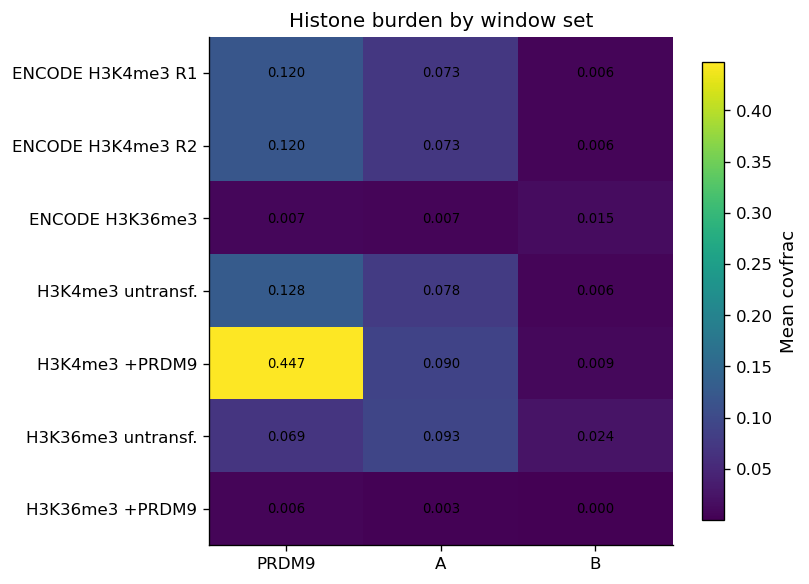

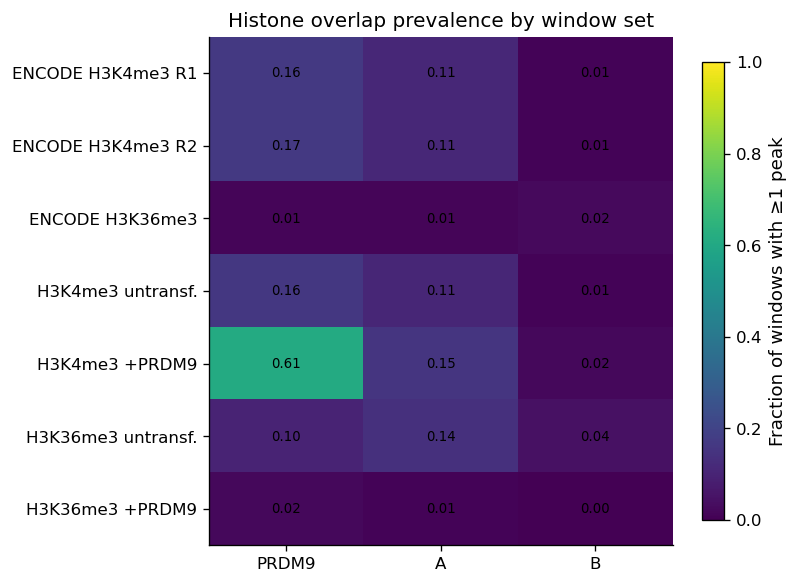

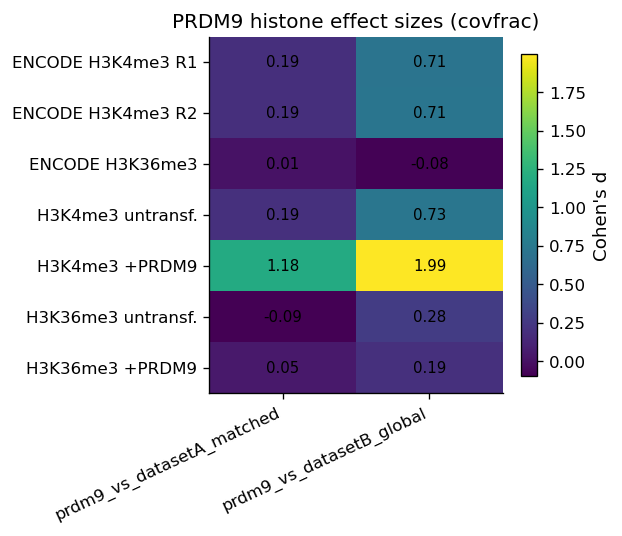

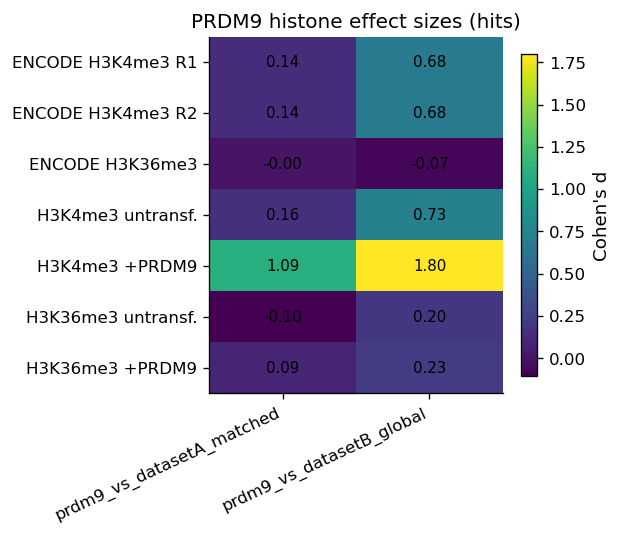

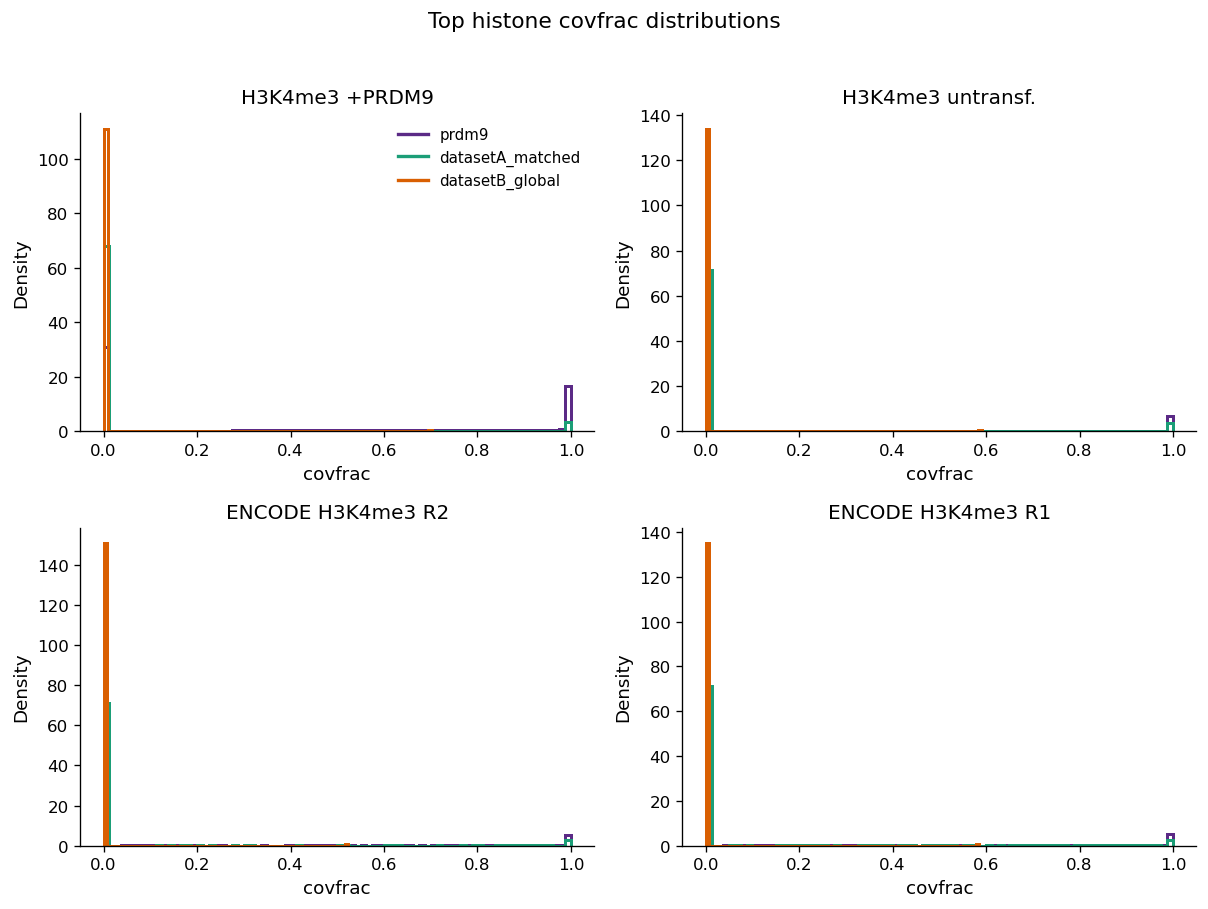

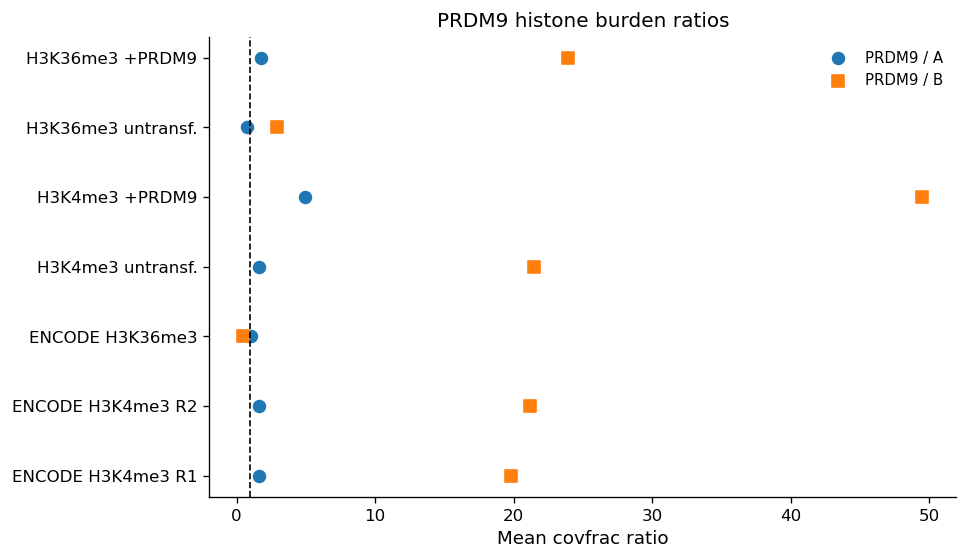

In [10]:

# ------------------------------------------------------------------
# Publication-style validation figures
# ------------------------------------------------------------------
plot_df = all_out.copy()

track_order = list(HISTONE_TRACKS.keys())
track_labels = [human_track_label(t) for t in track_order]

# 1) Mean covfrac heatmap
covfrac_mean_mat = pd.DataFrame(
    {
        ws: [
            plot_df.loc[plot_df["WindowSet"] == ws, featcol(track, "covfrac")].mean()
            for track in track_order
        ]
        for ws in ["prdm9", "datasetA_matched", "datasetB_global"]
    },
    index=track_order
)

fig, ax = plt.subplots(figsize=(6.8, 5.0))
im = ax.imshow(covfrac_mean_mat.to_numpy(dtype=float), aspect="auto")
ax.set_xticks(np.arange(covfrac_mean_mat.shape[1]))
ax.set_xticklabels(["PRDM9", "A", "B"])
ax.set_yticks(np.arange(covfrac_mean_mat.shape[0]))
ax.set_yticklabels(track_labels)
for i in range(covfrac_mean_mat.shape[0]):
    for j in range(covfrac_mean_mat.shape[1]):
        val = covfrac_mean_mat.iloc[i, j]
        ax.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=8)
cbar = fig.colorbar(im, ax=ax, shrink=0.9)
cbar.set_label("Mean covfrac")
ax.set_title("Histone burden by window set")
fig.tight_layout()
fig.savefig(FIGDIR / "histone_mean_covfrac_heatmap.png", bbox_inches="tight")
plt.show()

# 2) Prevalence of any overlap
prevalence_mat = pd.DataFrame(
    {
        ws: [
            (plot_df.loc[plot_df["WindowSet"] == ws, featcol(track, "hits")] > 0).mean()
            for track in track_order
        ]
        for ws in ["prdm9", "datasetA_matched", "datasetB_global"]
    },
    index=track_order
)

fig, ax = plt.subplots(figsize=(6.8, 5.0))
im = ax.imshow(prevalence_mat.to_numpy(dtype=float), aspect="auto", vmin=0, vmax=1)
ax.set_xticks(np.arange(prevalence_mat.shape[1]))
ax.set_xticklabels(["PRDM9", "A", "B"])
ax.set_yticks(np.arange(prevalence_mat.shape[0]))
ax.set_yticklabels(track_labels)
for i in range(prevalence_mat.shape[0]):
    for j in range(prevalence_mat.shape[1]):
        val = prevalence_mat.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8)
cbar = fig.colorbar(im, ax=ax, shrink=0.9)
cbar.set_label("Fraction of windows with ≥1 peak")
ax.set_title("Histone overlap prevalence by window set")
fig.tight_layout()
fig.savefig(FIGDIR / "histone_prevalence_heatmap.png", bbox_inches="tight")
plt.show()

# 3) PRDM9 vs background effect heatmaps
effect_plot = effect_df.copy()
effect_plot["track_label"] = effect_plot["track_name"].map(human_track_label)

for metric in ["covfrac", "hits"]:
    sub = effect_plot.loc[effect_plot["metric"] == metric].copy()
    mat = sub.pivot(index="track_label", columns="comparison", values="cohens_d").reindex(track_labels)
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    im = ax.imshow(mat.to_numpy(dtype=float), aspect="auto")
    ax.set_xticks(np.arange(mat.shape[1]))
    ax.set_xticklabels(mat.columns, rotation=25, ha="right")
    ax.set_yticks(np.arange(mat.shape[0]))
    ax.set_yticklabels(mat.index)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            val = mat.iloc[i, j]
            if pd.notna(val):
                ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9)
    cbar = fig.colorbar(im, ax=ax, shrink=0.9)
    cbar.set_label("Cohen's d")
    ax.set_title(f"PRDM9 histone effect sizes ({metric})")
    fig.tight_layout()
    fig.savefig(FIGDIR / f"histone_effect_heatmap_{metric}.png", bbox_inches="tight")
    plt.show()

# 4) Distribution panels for the four strongest covfrac effects
rank_df = effect_df.loc[effect_df["metric"] == "covfrac"].copy()
rank_df["abs_cohens_d"] = rank_df["cohens_d"].abs()
top_tracks = (
    rank_df.groupby("track_name", sort=False)["abs_cohens_d"]
    .max()
    .sort_values(ascending=False)
    .head(4)
    .index
    .tolist()
)

fig, axes = plt.subplots(2, 2, figsize=(10.2, 7.4))
axes = axes.ravel()

for ax, track_name in zip(axes, top_tracks):
    col = featcol(track_name, "covfrac")
    for ws in ["prdm9", "datasetA_matched", "datasetB_global"]:
        sub = plot_df.loc[plot_df["WindowSet"] == ws, col].astype(float)
        sub = quantile_clip_series(sub, 0.0, 0.995)
        ax.hist(
            sub,
            bins=80,
            density=True,
            histtype="step",
            linewidth=1.8,
            color=PALETTE_WINDOWSET[ws],
            label=ws,
        )
    ax.set_title(human_track_label(track_name))
    ax.set_xlabel("covfrac")
    ax.set_ylabel("Density")

handles = [Line2D([0], [0], color=PALETTE_WINDOWSET[ws], lw=2, label=ws) for ws in ["prdm9", "datasetA_matched", "datasetB_global"]]
axes[0].legend(handles=handles, frameon=False, loc="best")
fig.suptitle("Top histone covfrac distributions", y=1.02, fontsize=13)
fig.tight_layout()
fig.savefig(FIGDIR / "histone_top_covfrac_distributions.png", bbox_inches="tight")
plt.show()

# 5) Point-range summary of mean covfrac ratios
ratio_rows = []
for track_name in track_order:
    prdm9_mean = plot_df.loc[plot_df["WindowSet"] == "prdm9", featcol(track_name, "covfrac")].mean()
    a_mean = plot_df.loc[plot_df["WindowSet"] == "datasetA_matched", featcol(track_name, "covfrac")].mean()
    b_mean = plot_df.loc[plot_df["WindowSet"] == "datasetB_global", featcol(track_name, "covfrac")].mean()
    ratio_rows.append({
        "track_name": track_name,
        "PRDM9 / A": safe_ratio(prdm9_mean, a_mean),
        "PRDM9 / B": safe_ratio(prdm9_mean, b_mean),
    })
ratio_df = pd.DataFrame(ratio_rows).set_index("track_name").reindex(track_order)

fig, ax = plt.subplots(figsize=(8.2, 4.8))
ypos = np.arange(len(track_order))
ax.scatter(ratio_df["PRDM9 / A"], ypos, s=50, label="PRDM9 / A")
ax.scatter(ratio_df["PRDM9 / B"], ypos, s=50, marker="s", label="PRDM9 / B")
ax.axvline(1.0, color="black", lw=1.0, linestyle="--")
ax.set_yticks(ypos)
ax.set_yticklabels(track_labels)
ax.set_xlabel("Mean covfrac ratio")
ax.set_title("PRDM9 histone burden ratios")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGDIR / "histone_covfrac_ratio_summary.png", bbox_inches="tight")
plt.show()


In [11]:

# ------------------------------------------------------------------
# Compact on-notebook summaries
# ------------------------------------------------------------------
display(track_meta_df)

summary_small = effect_df.loc[effect_df["metric"] == "covfrac", [
    "comparison", "track_name", "prdm9_mean", "background_mean", "mean_ratio", "cohens_d"
]].copy()
summary_small["track_name"] = summary_small["track_name"].map(human_track_label)
summary_small = summary_small.sort_values(["comparison", "cohens_d"], ascending=[True, False]).reset_index(drop=True)
display(summary_small.head(20))

console.print(Panel.fit(
    "\n".join([
        "[bold green]Histone production notebook completed[/bold green]",
        f"Main features: {ALL_PARQUET}",
        f"Debug features: {DEBUG_PARQUET}",
        f"Summary table: {SUMMARY_TABLE}",
        f"Effect table: {EFFECT_TABLE}",
        f"Figures: {FIGDIR}",
        f"Log: {LOG_PATH}",
    ]),
    title="Outputs"
))


,track_name,track_name_sanitized,path,n_raw_rows,n_bad_numeric_rows,n_non_positive_rows,n_non_canonical_rows,n_exact_duplicate_rows_removed,n_clean_rows,peak_length_median_bp,peak_length_mean_bp,chromosomes_present
0,ENCODE_HEK_H3K36me3_R1_2,ENCODE_HEK_H3K36me3_R1_2,histone_marks/ENCFF224LEB_HEK_H3K36me3_R1_2_hg...,29492,0,0,0,0,29492,905.0,1241.547064,23
1,ENCODE_HEK_H3K4me3_R1,ENCODE_HEK_H3K4me3_R1,histone_marks/ENCFF498ERO_HEK_H3K4me3_R1_hg38.bed,30285,0,0,12,0,30273,628.0,943.111221,23
2,ENCODE_HEK_H3K4me3_R2,ENCODE_HEK_H3K4me3_R2,histone_marks/ENCFF127YXW_HEK_H3K4me3_R2_hg38.bed,30670,0,0,14,0,30656,573.0,895.264124,23
3,HEK_H3K36me3_PRDM9_transfected,HEK_H3K36me3_PRDM9_transfected,histone_marks/HEK293_H3K36me3_PRDM9-B-HA_trans...,3065,0,0,54,0,3011,297.0,370.402524,24
4,HEK_H3K36me3_untransfected,HEK_H3K36me3_untransfected,histone_marks/HEK293_H3K36me3_untransfected.bed,80375,0,0,1430,0,78945,466.0,850.878662,24
5,HEK_H3K4me3_PRDM9_transfected,HEK_H3K4me3_PRDM9_transfected,histone_marks/HEK293_H3K4me3_PRDM9-B_HA_transf...,76878,0,0,2448,0,74430,637.0,901.765363,24
6,HEK_H3K4me3_untransfected,HEK_H3K4me3_untransfected,histone_marks/HEK293_H3K4me3_untransfected.bed,19854,0,0,1337,0,18517,1490.0,1591.266512,24


,comparison,track_name,prdm9_mean,background_mean,mean_ratio,cohens_d
0,prdm9_vs_datasetA_matched,H3K4me3 +PRDM9,0.447074,0.089862,4.975101,1.184923
1,prdm9_vs_datasetA_matched,H3K4me3 untransf.,0.128422,0.077515,1.656743,0.192183
2,prdm9_vs_datasetA_matched,ENCODE H3K4me3 R2,0.120371,0.072790,1.653684,0.189201
3,prdm9_vs_datasetA_matched,ENCODE H3K4me3 R1,0.120262,0.072780,1.652402,0.188890
4,prdm9_vs_datasetA_matched,H3K36me3 +PRDM9,0.005542,0.003185,1.739833,0.052156
5,prdm9_vs_datasetA_matched,ENCODE H3K36me3,0.007247,0.006873,1.054450,0.005157
6,prdm9_vs_datasetA_matched,H3K36me3 untransf.,0.069138,0.093050,0.743025,-0.093347
7,prdm9_vs_datasetB_global,H3K4me3 +PRDM9,0.447074,0.009032,49.499378,1.994869
8,prdm9_vs_datasetB_global,H3K4me3 untransf.,0.128422,0.005980,21.475178,0.728977
9,prdm9_vs_datasetB_global,ENCODE H3K4me3 R2,0.120371,0.005691,21.150093,0.714278


╭──────────────────────────────────────── Outputs ─────────────────────────────────────────╮
│ Histone production notebook completed                                                    │
│ Main features: data_prdm9_histones_production/features/histone_features.parquet          │
│ Debug features: data_prdm9_histones_production/features/histone_features_with_qc.parquet │
│ Summary table: data_prdm9_histones_production/tables/histone_windowset_summary.tsv       │
│ Effect table: data_prdm9_histones_production/tables/histone_effect_summary.tsv           │
│ Figures: data_prdm9_histones_production/figures                                          │
│ Log: data_prdm9_histones_production/logs/histone_feature_generation.log                  │
╰──────────────────────────────────────────────────────────────────────────────────────────╯